# Models without spatial information

Linear, LSTM and TCN, trained with BasicTS on METR-LA (settings in `src/train/config.py`):
- 12 steps in → 12 out;
- one model shared by all sensors;
- missing values (0) handled as in DCRNN;
- scaler from the training data (mean 54.41, std 19.49); 
- early stopping on validation MAE;
- test set evaluated once at the end, seed 42; 
- LSTM and TCN: 10 epochs only (CPU time).

In [29]:
import torch
from src.model.baseline_temporal_models.linear import Linear, LinearConfig
from src.model.baseline_temporal_models.lstm import LSTM, LSTMConfig
from src.model.baseline_temporal_models.tcn import TCN, TCNConfig

torch.manual_seed(0)
x = torch.randn(2, 12, 207)            # 2 windows, 12 steps, 207 sensors
x2 = x.clone()
x2[:, :, 5] += 10                      # change ONLY sensor 5's input

for name, m in [('Linear', Linear(LinearConfig())), ('LSTM', LSTM(LSTMConfig())), ('TCN', TCN(TCNConfig()))]:
    with torch.no_grad():
        diff = (m(x2) - m(x)).abs().amax(dim=(0, 1))      # biggest change in each sensor's output
    print(f'{name}: output changed for sensors {torch.nonzero(diff > 1e-6).flatten().tolist()}')

Linear: output changed for sensors [5]
LSTM: output changed for sensors [5]
TCN: output changed for sensors [5]


Changing one sensor's input only changes that sensor's forecast: the models use no information from other sensors.

In [30]:
import json
from pathlib import Path

import pandas as pd

rows = []
for path in Path('checkpoints').glob('*/METR-LA_*_12_12/*/test_metrics.json'):
    model, run = path.parts[-4], path.parts[-3]          # e.g. 'LSTM', 'METR-LA_10_12_12'
    m = json.loads(path.read_text())
    for h, minutes in [(3, 15), (6, 30), (12, 60)]:
        r = m[f'horizon_{h}']
        rows.append({'model': model, 'run': run, 'minutes': minutes,
                     'MAE': r['MAE'], 'RMSE': r['RMSE'], 'MAPE %': 100 * r['MAPE']})

table = pd.DataFrame(rows).pivot_table(index=['model', 'run'], columns='minutes',
                                       values=['MAE', 'RMSE', 'MAPE %']).round(2)
table

MAE             MAPE %                RMSE         \
minutes                     15    30    60     15     30     60    15     30   
model  run                                                                     
LSTM   METR-LA_100_12_12  3.22  3.90  5.03   8.78  11.10  15.04  6.29   7.81   
       METR-LA_10_12_12   3.27  3.96  5.08   9.14  11.46  15.34  6.40   7.89   
Linear METR-LA_100_12_12  3.81  4.81  6.28   9.37  12.32  17.14  8.17  10.25   
       METR-LA_2_12_12    4.13  5.02  6.67  10.20  12.89  18.17  8.53  10.35   
TCN    METR-LA_100_12_12  3.14  3.84  4.98   8.57  10.93  14.97  6.17   7.75   
       METR-LA_10_12_12   3.15  3.85  4.99   8.58  10.96  14.81  6.16   7.73   

                                 
minutes                      60  
model  run                       
LSTM   METR-LA_100_12_12   9.83  
       METR-LA_10_12_12    9.88  
Linear METR-LA_100_12_12  12.37  
       METR-LA_2_12_12    12.62  
TCN    METR-LA_100_12_12   9.78  
       METR-LA_10_12_12    9.79

All three models beat the last-value rule at every horizon. TCN is best (MAE 3.15 / 3.85 / 4.99 at 15 / 30 / 60 min), slightly ahead of LSTM, with 2.6× fewer parameters (6 796 vs 17 932). LSTM and TCN beat both Step 1 rules at 15 and 30 minutes, but at 60 minutes the weekly average is still best (4.19). The linear model has a much higher RMSE (8.17 at 15 min), so it makes some very large errors; one possible cause is missing inputs (0 mph → −2.79 after scaling), which a linear model cannot ignore.

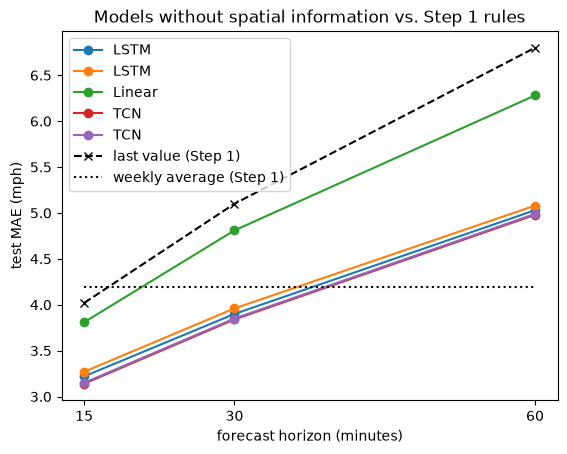

In [31]:
import matplotlib.pyplot as plt

mae = table['MAE']
for (model, run), row in mae.iterrows():
    if run == 'METR-LA_2_12_12':          # skip the 2-epoch test run
        continue
    plt.plot(row.index, row.values, marker='o', label=model)
plt.plot([15, 30, 60], [4.02, 5.10, 6.80], 'k--', marker='x', label='last value (Step 1)')
plt.plot([15, 30, 60], [4.19, 4.19, 4.19], 'k:', label='weekly average (Step 1)')
plt.xticks([15, 30, 60])
plt.xlabel('forecast horizon (minutes)')
plt.ylabel('test MAE (mph)')
plt.title('Models without spatial information vs. Step 1 rules')
plt.legend()
plt.savefig('notebooks/plots/step2_mae_by_horizon.png', dpi=150, bbox_inches='tight')
plt.show()

Linear stopped early after 31 epochs (best at 21) and is fully trained. LSTM and TCN were limited to 10 epochs (about 2 min per epoch on CPU). TCN had flattened out, but LSTM was still improving at epoch 10, so its result is preliminary.

In [32]:
import glob, torch
path = glob.glob('checkpoints/TCN/METR-LA_10_12_12/*/TCN_best_val_MAE.pt')[0]
weights = torch.load(path, map_location='cpu', weights_only=False)['model_state_dict']
weights['blocks.0.conv.weight'][:, 0, :].round(decimals=2)    # 32 rows: [weight on x(t-1), weight on x(t)]

tensor([[ 0.4700,  0.4500],
        [-0.3200,  0.4300],
        [-0.0500,  0.1500],
        [-0.3200,  0.2700],
        [ 0.4700, -0.4900],
        [ 0.4100,  0.1300],
        [ 0.5400,  0.0700],
        [ 0.1800, -0.0100],
        [ 0.4500,  0.0900],
        [-0.3000,  0.1700],
        [-0.2200, -0.0600],
        [-0.2800,  0.4100],
        [-0.3600, -0.1400],
        [-0.1200, -0.2500],
        [ 0.1000, -0.5200],
        [ 0.5300, -0.4400],
        [ 0.3200,  0.1300],
        [-0.0400,  0.2000],
        [ 0.0600,  0.4700],
        [ 0.1200, -0.0800],
        [ 0.1500, -0.1600],
        [ 0.0100,  0.1900],
        [ 0.2800, -0.2500],
        [ 0.0600,  0.0600],
        [ 0.0600, -0.1700],
        [-0.5600, -0.1800],
        [-0.2700,  0.3600],
        [ 0.0800,  0.1700],
        [ 0.1700,  0.0100],
        [ 0.4300, -0.4400],
        [-0.0000, -0.2100],
        [ 0.2000, -0.1700]])

In [33]:
import json
from pathlib import Path

import pandas as pd
import torch

runs = {'speed (12 steps)': Path('checkpoints/TCN/METR-LA_10_12_12')}          # your existing TCN run
runs.update({p.name.removeprefix('TCN_'): p for p in Path('checkpoints/features').glob('TCN_*')})

rows = []
for name, folder in runs.items():
    ckpt = next(folder.glob('*/TCN_best_val_MAE.pt'), None)
    if ckpt is None or not (ckpt.parent / 'test_metrics.json').exists():
        continue                                                 # run not finished yet
    best = torch.load(ckpt, map_location='cpu', weights_only=False)
    test = json.loads((ckpt.parent / 'test_metrics.json').read_text())
    rows.append({'inputs': name, 'best epoch': best['epoch'], 'val MAE': best['best_metrics']['val/MAE'],
                 'test MAE 15': test['horizon_3']['MAE'], 'test MAE 30': test['horizon_6']['MAE'],
                 'test MAE 60': test['horizon_12']['MAE']})
pd.DataFrame(rows).round(3)


,inputs,best epoch,val MAE,test MAE 15,test MAE 30,test MAE 60
0,speed (12 steps),9,3.474,3.150,3.854,4.995
1,speed+tod,7,3.410,3.126,3.766,4.752
2,speed+tod+dow,10,3.344,3.115,3.740,4.651
3,speed_in24,9,3.449,3.142,3.835,4.954
4,speed_in36,10,3.412,3.117,3.803,4.922


Each input was tested on its own on the TCN (10 epochs each) and kept only if the validation MAE dropped.
- Time of day (sine/cosine) lowers the validation MAE from 3.474 to 3.410, and adding day of week lowers it further to 3.344. The gain is largest at 60 minutes (4.99 → 4.65), where the gap to the weekly average shrinks from 0.80 to 0.46 mph.
- A longer input also helps: 24 steps gives 3.449 and 36 steps (3 hours) gives 3.412, about as much as time of day on validation. At 60 minutes, however, the gain is small (4.92, compared with 4.75 for time of day), and training is 3× slower.
- Best so far: speed + time of day + day of week. Not tested yet: 36 steps together with time of day and day of week. The best runs were still improving at epoch 10.

### Hyperparameter tuning (task 5)

Optuna, with the same rules for every model:
- the same budget: **10 tries per model**, each trained for **10 epochs**, judged on the **validation MAE** (the test set is not used);
- the same inputs: 12 steps of speed + time of day + day of week (best inputs from task 4), batch size 64;
- the first try (try 0) is the current settings, so the gain from tuning is measured directly;
- a try is **stopped early** if, from epoch 3 on, its validation MAE is worse than the median of the finished tries at the same epoch (the first 3 tries are never stopped). This saves time on settings that are clearly worse.

| Model | Settings searched | Current (try 0) |
|---|---|---|
| Linear | learning rate 0.0003–0.003 | 0.001 |
| TCN | channels 16 / 32 / 64, kernel 2 / 3, layers 4 / 5, learning rate | 32, 2, 4, 0.001 |
| LSTM | hidden units 32 / 64 / 128, layers 1 / 2, dropout 0–0.3 (2 layers only), learning rate | 64, 1, –, 0.001 |

Code: `src/utils/tuning/nn_tuning.py`; all tries are stored in `checkpoints/tuning/optuna.db`.

In [1]:
import matplotlib.pyplot as plt
import optuna
import pandas as pd
from matplotlib.lines import Line2D

optuna.logging.set_verbosity(optuna.logging.WARNING)
TUNED = ['Linear', 'TCN', 'LSTM']

rows = []
for name in TUNED:
    study = optuna.load_study(study_name=name, storage='sqlite:///checkpoints/tuning/optuna.db')
    best = study.best_trial.number                  # lowest validation MAE among the tries that finished
    for t in study.trials:
        curve = [t.intermediate_values[e] for e in sorted(t.intermediate_values)]   # validation MAE after each epoch
        stopped = t.state.name == 'PRUNED'
        role = 'current' if t.number == 0 else 'best' if t.number == best else 'stopped' if stopped else 'other'
        rows.append({'model': name, 'try': t.number, 'role': role, 'stopped': stopped, 'curve': curve,
                     'epochs': len(curve), 'val_mae': min(curve), **t.params,
                     'n_params': t.user_attrs['n_params'], 'minutes': t.user_attrs['minutes']})
tries = pd.DataFrame(rows)
tries.groupby('model', sort=False).agg(tries=('try', 'size'), stopped_early=('stopped', 'sum'))

,tries,stopped_early
model,,
Linear,10,7
TCN,10,1
LSTM,10,5


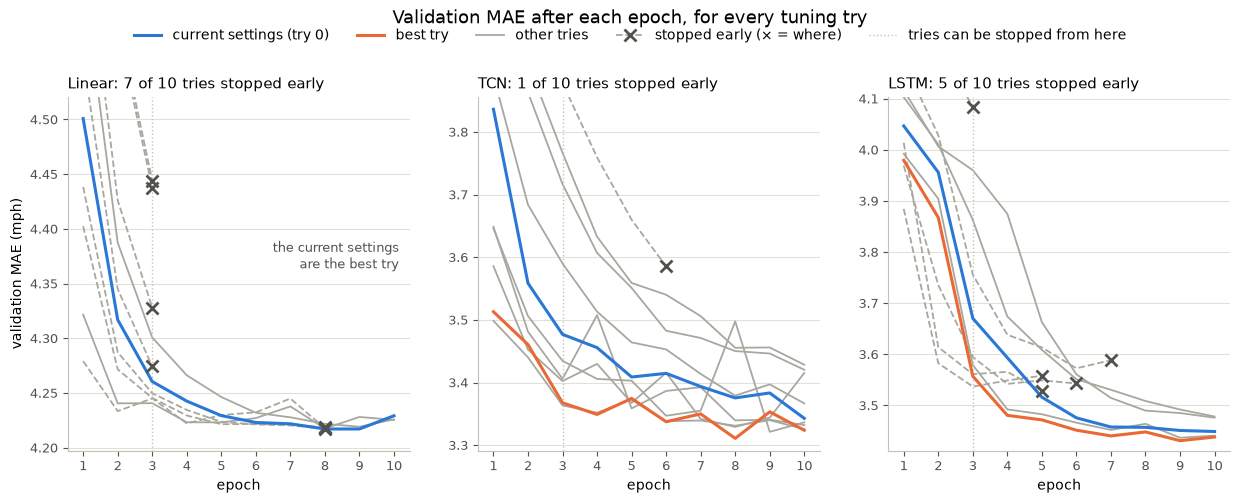

In [ ]:
COLORS = {'current': '#2a78d6', 'best': '#eb6834', 'other': '#a8a79f', 'stopped': '#a8a79f'}
INK2, GRID, AXIS = '#52514e', '#e1e0d9', '#c3c2b7'


def style(ax):
    ax.grid(axis='y', color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(AXIS)
    ax.tick_params(colors=INK2, labelsize=9)


draw_order = {'other': 0, 'stopped': 0, 'current': 1, 'best': 2}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, name in zip(axes, TUNED):
    sub = tries[tries.model == name].sort_values('role', key=lambda s: s.map(draw_order))
    for _, r in sub.iterrows():
        x = range(1, r.epochs + 1)
        if r.role in ('current', 'best'):
            ax.plot(x, r.curve, color=COLORS[r.role], lw=2.2, zorder=3)
        else:
            ax.plot(x, r.curve, color=COLORS[r.role], lw=1.3, ls='--' if r.stopped else '-', zorder=2)
        if r.stopped:
            ax.plot(r.epochs, r.curve[-1], 'x', color=INK2, ms=8, mew=2, zorder=4)
    current = sub[sub.role == 'current'].iloc[0]
    top = max(current.curve[0], *[c[-1] for c in sub[sub.stopped].curve]) + 0.02
    ax.set_ylim(sub.val_mae.min() - 0.02, top)                         
    ax.axvline(3, color=AXIS, lw=1, ls=':')
    ax.set_xticks(range(1, 11))
    ax.set_xlabel('epoch')
    ax.set_title(f'{name}: {sub.stopped.sum()} of {len(sub)} tries stopped early', fontsize=11, loc='left')
    if 'best' not in set(sub.role):
        ax.text(0.97, 0.55, 'the current settings\nare the best try', transform=ax.transAxes,
                ha='right', va='center', fontsize=9, color=INK2)
    style(ax)
axes[0].set_ylabel('validation MAE (mph)')
handles = [Line2D([], [], color=COLORS['current'], lw=2.2, label='current settings (try 0)'),
           Line2D([], [], color=COLORS['best'], lw=2.2, label='best try'),
           Line2D([], [], color=COLORS['other'], lw=1.3, label='other tries'),
           Line2D([], [], color=COLORS['stopped'], lw=1.3, ls='--', marker='x', mec=INK2, ms=8, mew=2,
                  label='stopped early (× = where)'),
           Line2D([], [], color=AXIS, lw=1, ls=':', label='tries can be stopped from here')]
fig.legend(handles=handles, loc='lower center', ncol=5, frameon=False, bbox_to_anchor=(0.5, 0.97), fontsize=10)
fig.suptitle('Validation MAE after each epoch, for every tuning try', y=1.07, fontsize=13)
plt.savefig('notebooks/plots/step2_tuning_curves.png', dpi=150, bbox_inches='tight')
plt.show()

Each line is one try: its validation MAE after every epoch (the y axes are zoomed in, so slow tries start above the top).
- Most of the improvement happens in the first 3–5 epochs, and by epoch 10 the curves are almost flat, so 10 epochs are enough to rank the settings. The TCN curves are noisier: a single epoch can jump by up to 0.14 mph (try 4 at epoch 8), so differences of 0.01–0.02 between the best TCN tries are not meaningful.
- **Linear:** 4 tries were stopped at epoch 3 (low learning rates, still far behind) and 3 more at epoch 8, when they were less than 0.001 mph above the median, which is noise. Every try that ran 8 epochs or more ended at 4.22.
- **TCN:** only one try was stopped (16 channels, kernel 3, learning rate 0.0005, clearly behind at epoch 6). The best try (orange) is below the current settings (blue) at every epoch.
- **LSTM:** all four 2-layer tries and the only 128-unit try were stopped. The 128-unit try was only 0.012 above the median at epoch 5 and still improving, so it might have caught up: "1 layer is best" is not certain.

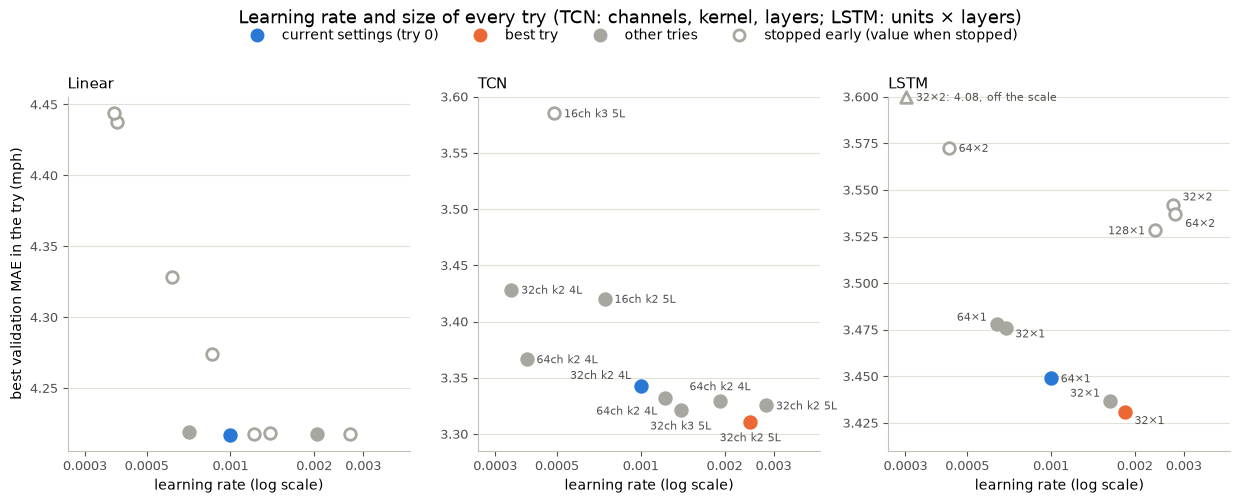

In [ ]:
YLIM = {'TCN': (3.285, 3.60),           
        'LSTM': (3.41, 3.60)}            
LABEL_POS = {('TCN', 0): (-7, 5, 'right'), ('TCN', 4): (0, -14, 'center'), ('TCN', 6): (-6, -12, 'right'),
             ('TCN', 7): (0, -14, 'center'), ('TCN', 8): (0, 8, 'center'),
             ('LSTM', 2): (-7, 2, 'right'), ('LSTM', 3): (7, -7, 'left'), ('LSTM', 4): (-7, 3, 'right'),
             ('LSTM', 5): (7, 3, 'left'), ('LSTM', 6): (7, -9, 'left'), ('LSTM', 7): (7, -9, 'left'),
             ('LSTM', 9): (-7, -3, 'right')}


def size_label(name, r):
    if name == 'TCN':
        return f'{r.channels:.0f}ch k{r.kernel_size:.0f} {r.num_layers:.0f}L'
    if name == 'LSTM':
        return f'{r.hidden_size:.0f}×{r.num_layers:.0f}'
    return ''


fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, name in zip(axes, TUNED):
    sub = tries[tries.model == name]
    lo, hi = YLIM.get(name, (None, None))
    for _, r in sub.iterrows():
        c = COLORS[r.role]
        off_scale = hi is not None and r.val_mae > hi
        y = hi if off_scale else r.val_mae
        ax.scatter(r.lr, y, s=70, marker='^' if off_scale else 'o', edgecolors=c,
                   facecolors='white' if r.stopped else c, linewidths=2, zorder=3, clip_on=False)
        label = size_label(name, r) + (f': {r.val_mae:.2f}, off the scale' if off_scale else '')
        if label:
            dx, dy, ha = LABEL_POS.get((name, r['try']), (7, -3, 'left'))
            ax.annotate(label, (r.lr, y), xytext=(dx, dy), textcoords='offset points', ha=ha, fontsize=8, color=INK2)
    if hi is not None:
        ax.set_ylim(lo, hi)
    ax.set_xscale('log')
    ax.set_xlim(2.6e-4, 4.4e-3)
    ticks = [3e-4, 5e-4, 1e-3, 2e-3, 3e-3]
    ax.set_xticks(ticks, [f'{t:g}' for t in ticks])
    ax.minorticks_off()
    ax.set_xlabel('learning rate (log scale)')
    ax.set_title(name, fontsize=11, loc='left')
    style(ax)
axes[0].set_ylabel('best validation MAE in the try (mph)')
dot = lambda color, face, label: Line2D([], [], ls='', marker='o', ms=8, mew=2, mec=color, mfc=face, label=label)
handles = [dot(COLORS['current'], COLORS['current'], 'current settings (try 0)'),
           dot(COLORS['best'], COLORS['best'], 'best try'),
           dot(COLORS['other'], COLORS['other'], 'other tries'),
           dot(COLORS['stopped'], 'white', 'stopped early (value when stopped)')]
fig.legend(handles=handles, loc='lower center', ncol=4, frameon=False, bbox_to_anchor=(0.5, 0.97), fontsize=10)
fig.suptitle('Learning rate and size of every try (TCN: channels, kernel, layers; LSTM: units × layers)',
             y=1.07, fontsize=13)
plt.savefig('notebooks/plots/step2_tuning_lr.png', dpi=150, bbox_inches='tight')
plt.show()

Each point is one try: its best validation MAE against its learning rate (hollow: stopped early, value when it was stopped).
- **Linear:** the learning rate changes only how fast the model learns, not where it ends (4.22). Linear has nothing to tune.
- **TCN:** the four lowest learning rates (0.00074 or less) are the four worst tries, and every try with a learning rate of 0.0012 or more beats the current settings (0.001). Within 10 epochs a higher learning rate simply learns more; with full training a lower one may catch up. Size matters less: 64 channels (26,636 parameters, 3.7× the current model) is not better than 32 channels, and 16 channels is worse. Learning rate and size change together in every try, so 10 tries cannot fully separate their effects.
- **LSTM:** the same pattern for the learning rate (higher is better, up to 0.0018). 32 units are as good as 64 at the same learning rate (3.476 vs 3.478) with 3.5× fewer parameters. The 2-layer tries with a high learning rate stalled around 3.54 after 3–4 epochs.

In [4]:
KEYS = {'Linear': ['lr'], 'TCN': ['channels', 'kernel_size', 'num_layers', 'lr'],
        'LSTM': ['hidden_size', 'num_layers', 'lr']}
summary = []
for name in TUNED:
    sub = tries[tries.model == name].set_index('try')
    cur, best = sub.loc[0], sub.loc[sub[~sub.stopped].val_mae.idxmin()]
    summary.append({'model': name,
                    'val MAE, current': round(cur.val_mae, 3), 'val MAE, best': round(best.val_mae, 3),
                    'gain': round(cur.val_mae - best.val_mae, 3), 'best try': best.name,
                    'best settings': ', '.join(f'{k}={best[k]:.4g}' for k in KEYS[name]),
                    'parameters (current -> best)': f'{cur.n_params:,} -> {best.n_params:,}'})
pd.DataFrame(summary).set_index('model')

,"val MAE, current","val MAE, best",gain,best try,best settings,parameters (current -> best)
model,,,,,,
Linear,4.217,4.217,0.000,0,lr=0.001,732 -> 732
TCN,3.343,3.311,0.032,7,"channels=32, kernel_size=2, num_layers=5, lr=0...","7,180 -> 9,260"
LSTM,3.449,3.431,0.018,7,"hidden_size=32, num_layers=1, lr=0.00184","18,956 -> 5,388"


**Gain from tuning** (validation MAE, 10-epoch tries): TCN 3.343 → 3.311 (−0.03), LSTM 3.449 → 3.431 (−0.02), Linear none.
- For comparison, adding time of day and day of week lowered the TCN validation MAE by 0.13 (3.474 → 3.344, task 4, same 10-epoch budget): the inputs matter about 4× more than the settings. The TCN try 0 reproduces that task-4 run (3.343 vs 3.344).
- Bigger models did not help: the best LSTM is 3.5× smaller than the current one, and the 64-channel TCNs were not better than 32 channels. This suggests the models are limited by the information they get (one sensor's past and the time), not by their size, which is what the graph models of Step 3 change.
- Caveats: 10-epoch tries favour settings that learn fast (high learning rates); gains of 0.02–0.03 may be within the run-to-run variation (the seed runs of task 9 will show); the 2-layer and 128-unit LSTMs were stopped early (a full 10-epoch run of the 128-unit settings would check this).
- Next: the best settings are trained fully (up to 100 epochs, early stopping) and evaluated once on the test set.

### Finding where the model fails

Load the errors:

In [34]:
import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd


def load_errors(model, run):
    """Absolute test errors [windows, 12 steps, 207 sensors] in mph, NaN where the target is missing.
    BasicTS writes the results as raw binary despite the .npy name, so np.load fails: use np.fromfile."""
    run_dir = next(Path(f'checkpoints/{model}/{run}').glob('*/'))
    read = lambda name: np.fromfile(run_dir / 'test_results' / name, dtype=np.float32).reshape(-1, 12, 207)
    pred, true = read('prediction.npy'), read('targets.npy')
    return np.where(true != 0, np.abs(pred - true), np.nan)


errors = {'Linear': load_errors('Linear', 'METR-LA_100_12_12'),
          'LSTM': load_errors('LSTM', 'METR-LA_10_12_12'),
          'TCN': load_errors('TCN', 'METR-LA_10_12_12')}


Place the error per sensor on the map:

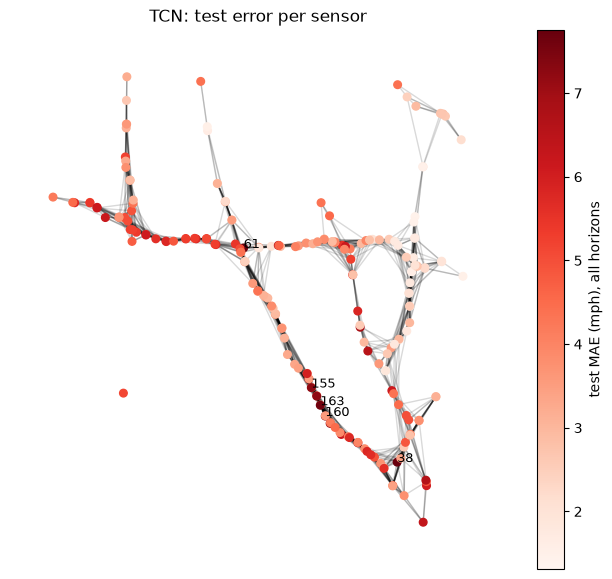

In [35]:
per_sensor = np.nanmean(errors['TCN'], axis=(0, 1))            # one MAE per sensor

loc = pd.read_csv('data/METR-LA/graph_sensor_locations.csv')
with open('data/METR-LA/adj_mx.pkl', 'rb') as f:
    sensor_ids, _, adj = pickle.load(f, encoding='latin1')
A = adj.copy()
np.fill_diagonal(A, 0)
G = nx.from_numpy_array(A > 0, create_using=nx.DiGraph)
pos = {i: (loc.longitude[i], loc.latitude[i]) for i in range(207)}

plt.figure(figsize=(8, 7))
nx.draw_networkx_edges(G, pos, alpha=0.15, arrows=False)
nodes = nx.draw_networkx_nodes(G, pos, nodelist=list(range(207)), node_color=per_sensor, cmap='Reds', node_size=30)
plt.colorbar(nodes, label='test MAE (mph), all horizons')
for i in np.argsort(per_sensor)[-5:]:                          # label the 5 worst sensors
    plt.annotate(str(i), pos[i], fontsize=9)
plt.title('TCN: test error per sensor')
plt.axis('off')
plt.savefig('notebooks/plots/step2_error_map.png', dpi=150, bbox_inches='tight')
plt.show()


Per-sensor test MAE ranges from 1.3 to 7.8 mph (median 3.7). [Describe where the worst sensors are: scattered, or clustered on one stretch of road? Name them.]

### Error by time of day

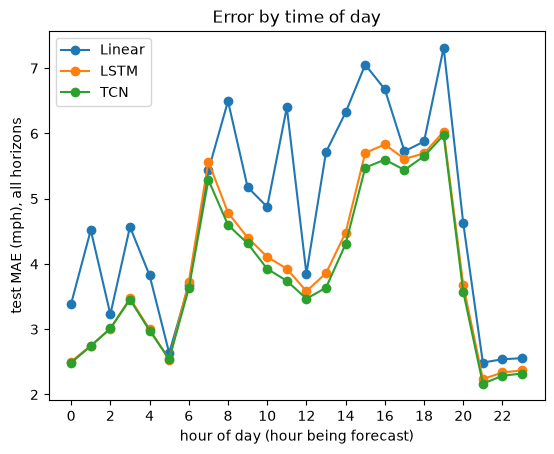

In [36]:
ts = np.load('data/METR-LA/test_timestamps.npy')
W = errors['TCN'].shape[0]
idx = np.arange(W)[:, None] + 12 + np.arange(12)[None, :]     # time step of every target in the test split
hour = (ts[idx, 0] * 24).astype(int)                          # its hour of day, shape [windows, 12]

for name, err in errors.items():
    plt.plot(range(24), [np.nanmean(err[hour == h]) for h in range(24)], marker='o', label=name)
plt.xticks(range(0, 24, 2))
plt.xlabel('hour of day (hour being forecast)')
plt.ylabel('test MAE (mph), all horizons')
plt.title('Error by time of day')
plt.legend()
plt.savefig('notebooks/plots/step2_error_by_hour.png', dpi=150, bbox_inches='tight')
plt.show()

Errors are grouped by the hour of the value being predicted, not the hour when the forecast was made: a 60-minute forecast made at 16:00 counts under 17:00.

Errors are lowest at night and highest in the rush hours, about twice as large around 17:00–19:00 as at night. Errors are larger when traffic changes quickly.

60 minute forecasts compared to weekly average:

weekly average MAE (60-min targets): 4.19


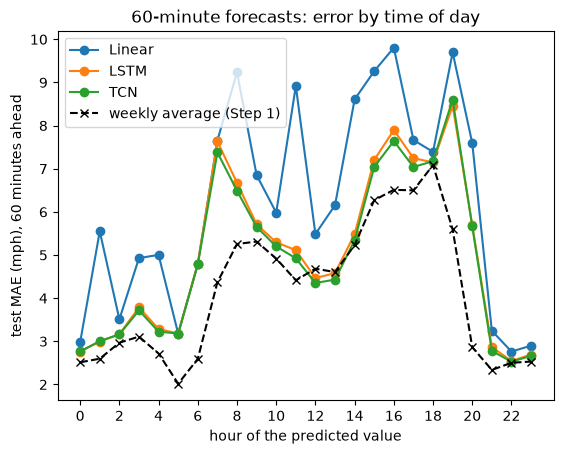

In [37]:
def week_slot(t):
    """Timestamps [..., 2] -> slot 0..2015 of the week (day of week * 288 + 5-min step of the day)."""
    return (np.round(t[..., 1] * 7).astype(int) % 7) * 288 + np.round(t[..., 0] * 288).astype(int) % 288

# weekly-average rule from Step 1: mean speed per (day of week, time of day) slot, from the training data
train = np.load('data/METR-LA/train_data.npy')
train_slot = week_slot(np.load('data/METR-LA/train_timestamps.npy'))
train = np.where(train == 0, np.nan, train)                            # skip missing values in the average
week = np.stack([np.nanmean(train[train_slot == s], axis=0) for s in range(2016)])   # [2016 slots, 207]

# its errors on the same 60-minute targets as the models
test = np.load('data/METR-LA/test_data.npy')
t60 = idx[:, 11]                                                       # time step of each 60-min target
true60 = test[t60]                                                     # [windows, 207]
err_week = np.where(true60 != 0, np.abs(week[week_slot(ts[t60])] - true60), np.nan)
print('weekly average MAE (60-min targets): %.2f' % np.nanmean(err_week))   # should be 4.19, as in Step 1

hour60 = hour[:, 11]                                                   # hour of each 60-min target
for name, err in errors.items():
    plt.plot(range(24), [np.nanmean(err[:, 11][hour60 == h]) for h in range(24)], marker='o', label=name)
plt.plot(range(24), [np.nanmean(err_week[hour60 == h]) for h in range(24)], 'k--', marker='x', label='weekly average (Step 1)')
plt.xticks(range(0, 24, 2))
plt.xlabel('hour of the predicted value')
plt.ylabel('test MAE (mph), 60 minutes ahead')
plt.title('60-minute forecasts: error by time of day')
plt.legend()
plt.savefig('notebooks/plots/step2_error_by_hour_60min.png', dpi=150, bbox_inches='tight')
plt.show()


One hour ahead, the weekly average beats all models for most of the day, especially at the start of the morning rush (06–08) and the end of the evening rush (19–20): from the last hour alone, a model cannot know that a rush is about to start or end. Around midday the models are as good as the weekly average.